# La capacidad de contrapeso: recortes, capacidad de monetización y pérdidas en cartera a vencimiento

**Pregunta:** ¿Cuánto efectivo puede reunir el banco que quebró en marzo de 2023 contra sus valores, con qué rapidez, y cuántos días de supervivencia le quita la pérdida no realizada de su cartera mantenida a vencimiento?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 y 02 de este tema
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook puedes:

- calcular el valor de liquidez de una clase de activos (valor de mercado, menos la parte gravada, menos un recorte) y decir qué regla dio cada recorte;
- convertir los valores de liquidez en una capacidad de contrapeso (CBC) que crece día a día con un calendario de monetización;
- medir cómo la pérdida no realizada de una cartera mantenida a vencimiento (HTM) quita CBC y acorta el período de supervivencia;
- leer las pruebas del producto sobre las reglas de recorte, sobre el efecto HTM y sobre la revaluación de la cartera HTM, y los días de supervivencia que cuesta la pérdida.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
# Etiquetas en español de los semáforos de las pruebas de validación
LIGHTS = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Dos documentos versionados del caso C16 (agregados reales del reporte de llamada de la FDIC del banco que quebró el 2023-03-10 hasta el 2022-12-31, comportamiento y depósitos sintéticos, clase de licencia `mirror-allowed`):

- `data/derived/C16/list-adverse.json`: las clases del CBC al valor contable de los valores (la base de costo amortizado), las convenciones de los recortes y del calendario de monetización, y el período de supervivencia.
- `data/derived/C16/htm-losses.json`: la misma escalera con la cartera de valores a valor razonable, el efecto de la pérdida sobre el CBC y las pruebas versionadas.

Los recortes del banco central son uno menos los márgenes de la ventana de descuento de la Reserva Federal vigentes el 2023-03-10 (Federal Reserve discount window, 2022-2023), tomados por clase del documento. Los montos están en miles de USD.

In [2]:
# Cargar los dos documentos versionados (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
folder = ROOT / "data" / "derived" / "C16"
adverse = json.loads((folder / "list-adverse.json").read_text(encoding="utf-8"))
htm_doc = json.loads((folder / "htm-losses.json").read_text(encoding="utf-8"))
out, htm_out = adverse["outputs"], htm_doc["outputs"]

for name, doc in (("list-adverse", adverse), ("htm-losses", htm_doc)):
    baked = doc["provenance"]["riskvalidation_version"]
    print(name, "| calculado con riskvalidation", baked, "| instalado", rv.__version__)
framework = out["cbc"]["haircut_framework"]
print("fecha de valoración:", out["valuation_date"])
print("marco de recortes vigente desde", framework["effective_from"], "hasta", framework["effective_to"])

list-adverse | calculado con riskvalidation 1.0.1 | instalado 1.0.1
htm-losses | calculado con riskvalidation 1.0.1 | instalado 1.0.1
fecha de valoración: 2022-12-31
marco de recortes vigente desde 2022-03-14 hasta 2023-03-12


## Método

### Paso 1: el valor de liquidez de un activo

El valor de liquidez de una clase de activos es su valor de mercado menos un recorte, y solo cuenta la parte no gravada (BCE, 2019, nota metodológica, párrafos 63 y 74). Con valor de mercado $M$, parte gravada $E$ y recorte $h$:

$$\mathrm{LV} = (M - E)\,(1 - h)$$

El reporte de llamada da los valores por tipo a su valor contable y el monto pignorado (`SCPLEDGE`); el documento reparte el monto pignorado a prorrata entre los tipos, un supuesto declarado. La celda siguiente toma las seis clases del documento, llama a `liquidity_value` para cada una e imprime la tabla.

In [3]:
# El valor de liquidez de cada clase desde su valor usado, su parte gravada y su recorte
from riskvalidation.liquidity.cbc import liquidity_value

classes = out["cbc"]["classes"]
values = [liquidity_value(c["value_used"], c["haircut"]["value"], c["encumbered"]) for c in classes]

columns = f"{'clase':18s}{'valor usado':>12s}{'gravado':>12s}{'recorte':>9s}{'valor de liquidez':>19s}"
print(columns, "  (miles de millones de USD)")
for c, lv in zip(classes, values):
    left = f"{c['class_id']:18s}{c['value_used'] / 1e6:12.3f}{c['encumbered'] / 1e6:12.3f}"
    print(left + f"{c['haircut']['value']:9.2f}{lv / 1e6:19.3f}")
total = sum(values)
print("valor de liquidez total (miles de millones de USD):", round(total / 1e6, 4))
print("proporción pignorada de los valores:", round(out["cbc"]["pledged"]["share_of_securities"], 4))

clase              valor usado     gravado  recorte  valor de liquidez   (miles de millones de USD)
cash-and-balances       12.511       0.000     0.00             12.511
treasury                16.043       7.571     0.02              8.302
mortgage-backed         91.460      43.164     0.04             46.364
other-agency             0.587       0.277     0.03              0.301
municipal                7.417       3.500     0.05              3.721
other-debt               1.796       0.848     0.50              0.474
valor de liquidez total (miles de millones de USD): 71.6726
proporción pignorada de los valores: 0.4719


La celda siguiente dibuja adónde va el valor de cada clase: contado como valor de liquidez, quitado por el recorte o gravado.

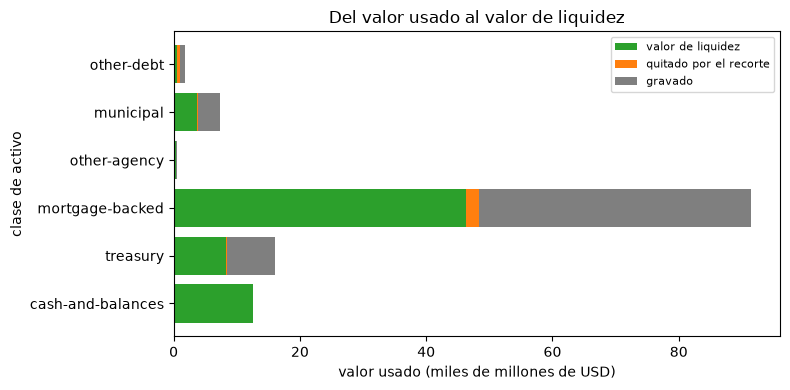

In [4]:
# Dibujar adónde va el valor de cada clase: valor de liquidez, quitado por el recorte o gravado
names = [c["class_id"] for c in classes]
encumbered = np.array([c["encumbered"] for c in classes]) / 1e6
counted = np.array(values) / 1e6
cut = np.array([c["value_used"] for c in classes]) / 1e6 - encumbered - counted
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(names, counted, color="tab:green", label="valor de liquidez")
ax.barh(names, cut, left=counted, color="tab:orange", label="quitado por el recorte")
ax.barh(names, encumbered, left=counted + cut, color="tab:gray", label="gravado")
ax.set_xlabel("valor usado (miles de millones de USD)")
ax.set_ylabel("clase de activo")
ax.set_title("Del valor usado al valor de liquidez")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Los valores respaldados por hipotecas dominan la pila: de 91,460 mil millones de USD en cartera, 43,164 están gravados y el resto, tras un recorte de 4%, deja 46,364 de valor de liquidez. Los bonos del Tesoro muestran el mismo patrón a menor escala (16,043 en cartera, 7,571 pignorados, 8,302 contados). Las barras grises son la mayor pérdida de capacidad: los valores pignorados son 0,4719 de la cartera de valores, mientras las porciones naranjas, los recortes, apenas se ven porque los márgenes de la ventana de descuento son generosos, entre 2% y 5%. El total es 71,6726 mil millones. La figura no dice con qué rapidez ese stock se vuelve efectivo, que es la pregunta del paso 3.

### Paso 2: qué regla dio el recorte

La nota fija un orden para el recorte de un activo (párrafo 74): el efectivo a valor nominal (recorte 0); un activo elegible para el banco central toma el recorte del banco central; si no puede determinarse, el recorte del LCR cuando el activo es de alta calidad líquida (HQLA) y 50% en otro caso; un activo negociable no elegible toma la tabla de acciones por clasificación (20%, 35%, 50%) o 30% si es HQLA y 50% si no. `haircut_rule` devuelve el recorte y la etiqueta de la regla que lo dio. La celda siguiente la aplica a las clases del documento, con el recorte del banco central de cada clase (uno menos el margen de la Reserva Federal) cuando el marco lo da.

In [5]:
# La regla de recorte de cada clase: el recorte del banco central si la Reserva Federal da un margen, si no el respaldo
from riskvalidation.liquidity.cbc import haircut_rule

mapping = {row["class_id"]: row for row in out["conventions"]["cbc_securities_mapping"]["rows"]}
print(f"{'clase':18s}{'margen':>9s}{'tramo de plazo':>16s}{'recorte':>9s}  regla que da el motor")
for c in classes:
    row = mapping[c["class_id"]]
    margin = row["margin"]
    central = None if margin is None else 1.0 - margin
    if c["class_id"] == "cash-and-balances":
        haircut, rule = haircut_rule("cash")
    else:
        haircut, rule = haircut_rule("non-equity", central_bank_eligible=True, central_bank_haircut=central)
    margin_text = "-" if margin is None else f"{margin:.2f}"
    bucket = "-" if row["duration_bucket"] == "none" else row["duration_bucket"]
    print(f"{c['class_id']:18s}{margin_text:>9s}{bucket:>16s}{haircut:9.2f}  {rule}")

clase                margen  tramo de plazo  recorte  regla que da el motor
cash-and-balances         -               -     0.00  nominal-value
treasury               0.98            >3-5     0.02  central-bank-framework
mortgage-backed        0.96           >5-10     0.04  central-bank-framework
other-agency           0.97            >3-5     0.03  central-bank-framework
municipal              0.95           >5-10     0.05  central-bank-framework
other-debt                -               -     0.50  fifty-percent-fallback


El producto además versiona una prueba que corre todo el orden de la nota sobre nueve casos construidos (las tres bandas de acciones, los casos HQLA y de respaldo, los casos de banco central, el efectivo). La celda siguiente la llama e imprime la regla que recibe cada caso.

In [6]:
# La prueba de reglas de recorte sobre nueve casos construidos: el orden de la nota, regla por regla
from riskvalidation.validation.liquidity import cbc_haircut_rules

rules = cbc_haircut_rules()
for case in rules.extras["cases"]:
    print(f"{case['kind']:12s} recorte y regla: {case['got']}")
print("casos:", rules.n, "| mayor diferencia:", rules.statistic, "| semáforo:", LIGHTS[rules.light.value])

equity       recorte y regla: [0.2, 'ecb-equity-table']
equity       recorte y regla: [0.35, 'ecb-equity-table']
equity       recorte y regla: [0.5, 'ecb-equity-table']
non-equity   recorte y regla: [0.3, 'ecb-non-equity-hqla']
non-equity   recorte y regla: [0.5, 'fifty-percent-fallback']
non-equity   recorte y regla: [0.04, 'central-bank-framework']
non-equity   recorte y regla: [0.15, 'lcr-haircut-hqla']
non-equity   recorte y regla: [0.5, 'fifty-percent-fallback']
cash         recorte y regla: [0.0, 'nominal-value']
casos: 9 | mayor diferencia: 0.0 | semáforo: verde


### Paso 3: del valor de liquidez a un CBC que crece por día

Los activos no son efectivo el día 1. Un calendario de monetización da la proporción acumulada del valor de liquidez que puede volverse efectivo hacia cada día, así que el CBC del día $d$ es:

$$\mathrm{CBC}(d) = \sum_{c} \mathrm{LV}_c \; \sigma(d)$$

donde $\sigma(d)$ es la proporción del último punto del calendario con día $\le d$ (cero antes del primer punto). El dosier nombra la capacidad por día pero no da un valor, así que el calendario del documento (50% el día 1, 80% el día 2, 100% el día 3) es una convención declarada, con una cota inmediata y una lenta. `cbc_stack` devuelve el CBC por clase; la celda siguiente lo imprime para el día 1 y muestra los tres calendarios en los días 1, 5 y 10.

In [7]:
# La pila de CBC por clase bajo el calendario del documento, y las cotas inmediata y lenta
from riskvalidation.liquidity.cbc import cbc_stack, monetisation_capacity

schedule = out["conventions"]["monetisation_schedule"]
points = [(p["day"], p["cumulative_share"]) for p in schedule["points"]]
inputs = {c["class_id"]: (c["value_used"], c["encumbered"], c["haircut"]["value"]) for c in classes}
stack = cbc_stack(inputs, points, 125)

print("calendario (día, proporción acumulada):", points)
print("CBC del día 1 por clase (miles de millones de USD):", {k: round(float(v[0]) / 1e6, 3) for k, v in stack.items()})
bands = schedule["sensitivity_band"]
bounds = {band["id"]: [(p["day"], p["cumulative_share"]) for p in band["points"]] for band in bands}
bounds["document"] = points
names = {"immediate": "inmediato", "slow": "lento", "document": "documento"}
paths = {names[name]: monetisation_capacity(total, pts, 125) for name, pts in bounds.items()}
for name, path in paths.items():
    at_days = [round(float(path[d - 1]) / 1e6, 2) for d in (1, 5, 10)]
    print(f"{name:10s} CBC en los días 1, 5 y 10 (miles de millones de USD):", at_days)

calendario (día, proporción acumulada): [(1, 0.5), (2, 0.8), (3, 1.0)]
CBC del día 1 por clase (miles de millones de USD): {'cash-and-balances': 6.255, 'treasury': 4.151, 'mortgage-backed': 23.182, 'other-agency': 0.15, 'municipal': 1.86, 'other-debt': 0.237}
inmediato  CBC en los días 1, 5 y 10 (miles de millones de USD): [71.67, 71.67, 71.67]
lento      CBC en los días 1, 5 y 10 (miles de millones de USD): [17.92, 43.0, 71.67]
documento  CBC en los días 1, 5 y 10 (miles de millones de USD): [35.84, 71.67, 71.67]


La celda siguiente dibuja el CBC en los primeros diez días bajo los tres calendarios.

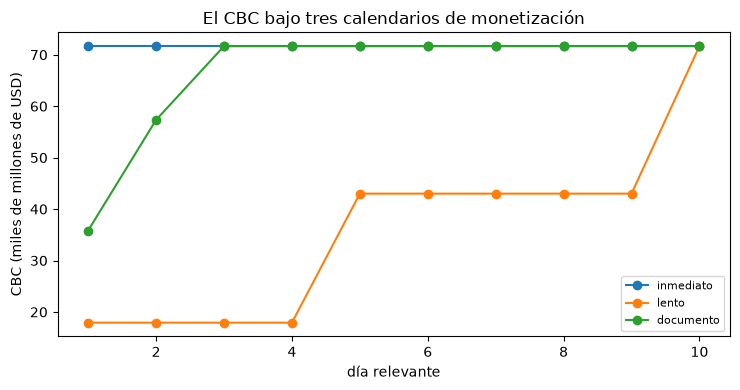

In [8]:
# Dibujar el CBC en los primeros diez días bajo los tres calendarios de monetización
fig, ax = plt.subplots(figsize=(7.5, 4))
for name, path in paths.items():
    ax.plot(range(1, 11), path[:10] / 1e6, marker="o", label=name)
ax.set_xlabel("día relevante")
ax.set_ylabel("CBC (miles de millones de USD)")
ax.set_title("El CBC bajo tres calendarios de monetización")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Las tres líneas llegan al mismo techo, 71,67 mil millones de USD, en días distintos. La cota inmediata lo tiene todo desde el día 1, el calendario del documento tiene 35,84 mil millones el día 1 y el monto completo al día 5, y la cota lenta avanza con 17,92 el día 1 y 43,00 el día 5 para llegar el día 10. Así el calendario mueve los primeros días de la escalera y nunca el total, por eso importa para una corrida que muerde en la primera semana. Es una convención declarada: el dosier de investigación nombra la capacidad por día y no da un valor. La figura no muestra la pérdida sobre los valores, que viene a continuación.

### Paso 4: la pérdida no realizada de una cartera mantenida a vencimiento

Una cartera mantenida a vencimiento se lleva a costo amortizado, así que el reporte de llamada esconde su pérdida de la imagen de liquidez; pero un banco que tiene que vender o pignorar esos valores en una tensión recibe su valor razonable, no su valor contable. Las pérdidas no realizadas reducen entonces el CBC efectivo y pueden gatillar corridas (Jiang et al., 2024; BCE, 2019). Para una clase con valor contable $K$, valor razonable $V$, parte gravada $E$ y recorte $h$:

$$\Delta = V - K, \qquad \mathrm{CBC}_{\text{with}} = (V - E)(1 - h), \qquad \mathrm{removed} = (K - E)(1 - h) - (V - E)(1 - h)$$

El reporte de llamada da el valor razonable informado de la cartera a vencimiento (`SCHF`) y de la disponible para la venta; no da la pérdida por tipo. El documento aplica la pérdida informada a toda la cartera de valores a prorrata por tipo, un supuesto declarado, nunca una pérdida informada por tipo. El monto gravado es el mismo en ambas bases. La celda siguiente corre `cbc_with_htm_loss` clase por clase.

In [9]:
# El CBC con y sin la pérdida, clase por clase, desde el motor; el efectivo no tiene pérdida
from riskvalidation.liquidity.cbc import cbc_with_htm_loss

htm = htm_out["htm"]
carrying = {c["class_id"]: c for c in classes}
without = carrying["cash-and-balances"]["liquidity_value"]
with_loss = without
by_class = {}
columns = f"{'clase':18s}{'pérdida no realizada':>22s}{'CBC sin':>10s}{'CBC con':>10s}{'quitado':>9s}"
print(columns, "  (miles de millones de USD)")
for c in htm_out["cbc"]["classes"]:
    if c["class_id"] == "cash-and-balances":
        continue
    base = carrying[c["class_id"]]
    result = cbc_with_htm_loss(base["carrying_value"], c["fair_value"], c["encumbered"], c["haircut"]["value"])
    without += result.cbc_without_loss
    with_loss += result.cbc_with_loss
    by_class[c["class_id"]] = (result.cbc_without_loss, result.cbc_with_loss)
    left = f"{c['class_id']:18s}{result.unrealised_loss / 1e6:22.3f}{result.cbc_without_loss / 1e6:10.3f}"
    print(left + f"{result.cbc_with_loss / 1e6:10.3f}{result.cbc_removed / 1e6:9.3f}")
print("CBC total sin y con la pérdida (miles de millones de USD):", round(without / 1e6, 4), round(with_loss / 1e6, 4))
print("quitado (miles de millones de USD):", round((without - with_loss) / 1e6, 4))

clase               pérdida no realizada   CBC sin   CBC con  quitado   (miles de millones de USD)
treasury                          -2.073     8.302     6.270    2.032
mortgage-backed                  -11.819    46.364    35.017   11.347
other-agency                      -0.076     0.301     0.227    0.074
municipal                         -0.958     3.721     2.810    0.911
other-debt                        -0.232     0.474     0.358    0.116
CBC total sin y con la pérdida (miles de millones de USD): 71.6726 57.1941
quitado (miles de millones de USD): 14.4785


La celda siguiente dibuja el CBC de cada clase a valor contable y con la pérdida no realizada.

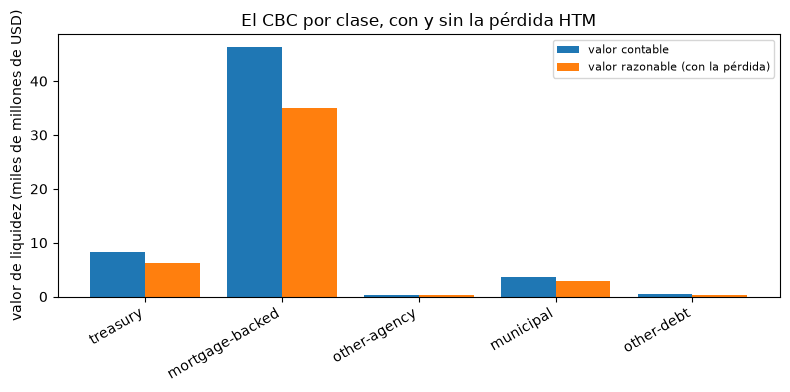

In [10]:
# Dibujar el CBC de cada clase a valor contable y con la pérdida no realizada de la cartera HTM
names = list(by_class)
position = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(position - 0.2, [by_class[k][0] / 1e6 for k in names], width=0.4, label="valor contable")
ax.bar(position + 0.2, [by_class[k][1] / 1e6 for k in names], width=0.4, label="valor razonable (con la pérdida)")
ax.set_xticks(position)
ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_ylabel("valor de liquidez (miles de millones de USD)")
ax.set_title("El CBC por clase, con y sin la pérdida HTM")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Los valores respaldados por hipotecas llevan la mayor parte del CBC y de la pérdida: su valor de liquidez cae de 46,364 a 35,017 mil millones de USD, 11,347 de los 14,4785 mil millones que la pérdida quita en total (de 71,6726 a 57,1941). Los bonos del Tesoro pierden una cuarta parte de lo suyo, 2,032 de 8,302 mil millones. La pérdida se reparte a prorrata por tipo porque el reporte de llamada no da ninguna por tipo, así que el reparto entre barras es un supuesto del producto y solo el total es una cifra informada. La figura no muestra el efecto sobre el período de supervivencia; ese es el paso siguiente.

### Paso 5: el efecto sobre el período de supervivencia

La prueba `liq.htm_loss_effect` toma el CBC y el período de supervivencia sin y con la pérdida y verifica el sentido del efecto: la pérdida no debe subir el CBC ni alargar el período de supervivencia. Su estadístico es el CBC quitado y su métrica la proporción del CBC quitada. Una luz verde dice que el efecto tiene el signo esperado, no que la pérdida sea pequeña. Los períodos de supervivencia son los de los dos documentos (LiST Adverso sobre el valor contable y sobre el valor razonable). La celda siguiente llama a la prueba.

In [11]:
# La prueba del efecto de la pérdida HTM: CBC y período de supervivencia sin y con la pérdida
from riskvalidation.validation.liquidity import htm_loss_effect

survival_without = out["path"]["survival"]["day"]
survival_with = htm_out["path"]["survival"]["day"]
effect = htm_loss_effect(without, with_loss, survival_without, survival_with)

print("período de supervivencia sin y con la pérdida (días):", survival_without, survival_with)
print("CBC quitado (miles de millones de USD):", round(effect.statistic / 1e6, 4))
print("proporción del CBC quitada:", round(effect.metric, 6), "| semáforo:", LIGHTS[effect.light.value])

período de supervivencia sin y con la pérdida (días): 62 44
CBC quitado (miles de millones de USD): 14.4785
proporción del CBC quitada: 0.202009 | semáforo: verde


La pérdida es también una perilla. `htm_loss_grid` escala la pérdida informada por un múltiplo (0 la quita, 1 es la pérdida informada) y el documento corre la escalera en cada múltiplo. La celda siguiente recalcula las pérdidas de la grilla a partir de la informada y las imprime con el CBC y el período de supervivencia que da la escalera del producto en cada múltiplo (esas dos columnas las calcula la cadena de procesamiento del producto; volver a correr la escalera es el trabajo del notebook 04).

In [12]:
# La grilla de pérdida HTM: las pérdidas del motor para cada múltiplo, con el CBC y el período de la escalera
from riskvalidation.liquidity.scenarios import htm_loss_grid

grid = out["sensitivities"]["htm_loss"]
multiples = [row["multiple"] for row in grid]
losses = htm_loss_grid(htm["reported"]["htm_unrealised"], multiples)

print(f"{'múltiplo':>9s}{'pérdida (mil millones USD)':>28s}{'CBC':>9s}{'día de supervivencia':>22s}")
for row, loss in zip(grid, losses):
    print(f"{row['multiple']:9.1f}{loss / 1e6:28.3f}{row['cbc'] / 1e6:9.2f}{row['survival']['day']:22d}")

 múltiplo  pérdida (mil millones USD)      CBC  día de supervivencia
      0.0                      -0.000    71.67                    62
      0.5                      -7.580    64.43                    53
      1.0                     -15.159    57.19                    44
      1.5                     -22.738    49.95                    36
      2.0                     -30.318    42.72                    28


La celda siguiente dibuja el período de supervivencia frente al múltiplo de la pérdida informada.

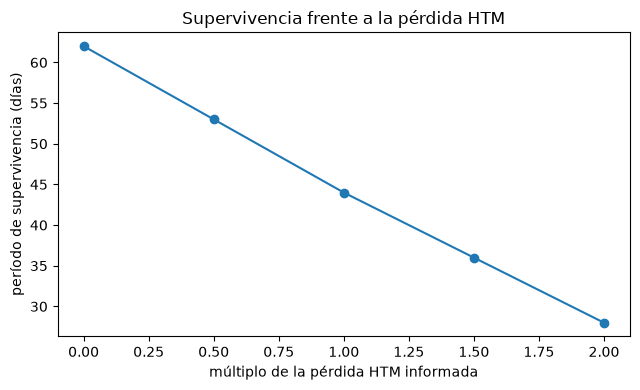

In [13]:
# Dibujar el período de supervivencia frente al múltiplo de la pérdida HTM informada
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(multiples, [row["survival"]["day"] for row in grid], marker="o")
ax.set_xlabel("múltiplo de la pérdida HTM informada")
ax.set_ylabel("período de supervivencia (días)")
ax.set_title("Supervivencia frente a la pérdida HTM")
fig.tight_layout()
plt.show()

La línea cae de manera sostenida: 62 días sin pérdida, 53 con la mitad de la pérdida informada, 44 con toda, 36 con una vez y media y 28 con el doble. Cada medio paso cuesta 8 o 9 días, así que el efecto es casi lineal en el rango probado, y la pérdida informada sola le quita 18 días de vida al banco. La escalera del producto da el CBC y el día de supervivencia de esta figura, y la pérdida no realizada es lo que el motor quita del CBC; la figura no dice cómo se habría financiado el banco contra los valores a la par, que es el contrafactual del paso 6.

### Paso 6: ¿reproduce el motor el valor razonable informado?

El producto no toma el valor razonable informado como cierto. La prueba `liq.htm_revaluation_vs_reported` revalúa la cartera HTM a partir de su perfil de vencimientos bajo la curva par del Tesoro (un bono par por tramo de vencimiento, con las curvas `irrbb` del motor) y la compara con el valor razonable informado $V_r$, como proporción de la pérdida no realizada informada:

$$\text{statistic} = \frac{|V_{\text{model}} - V_r|}{|V_r - K|}$$

La luz es una compuerta interna del producto (verde hasta 0,05, ámbar hasta 0,15, rojo por encima), no un umbral regulatorio. La revaluación está versionada en el documento; la celda siguiente llama a la prueba con esos insumos e imprime el contrafactual del Bank Term Funding Program que el documento también trae (valoración a la par anunciada el 2023-03-12, después de la corrida).

In [14]:
# La prueba de revaluación con la revaluación del documento, y el contrafactual a la par
from riskvalidation.validation.liquidity import htm_revaluation_vs_reported

revaluation = htm["revaluation"]
reported = htm["reported"]
check = htm_revaluation_vs_reported(
    revaluation["model_fair_value"], reported["htm_fair_value"], reported["htm_amortised_cost"]
)

print("valor razonable informado (miles de millones de USD):", round(reported["htm_fair_value"] / 1e6, 3))
print("revaluado por el modelo (miles de millones de USD):", round(revaluation["model_fair_value"] / 1e6, 3))
print("estadístico:", round(check.statistic, 6))
print("diferencia (miles de millones de USD):", round(check.metric / 1e6, 3))
print("semáforo:", LIGHTS[check.light.value])
par = htm["btfp_par"]
print("contrafactual a la par: CBC (miles de millones de USD):", round(par["cbc_at_par"] / 1e6, 3))
print("alza del CBC a la par (miles de millones de USD):", round(par["uplift"] / 1e6, 3))
print("valoración a la par anunciada el", par["announced"])

valor razonable informado (miles de millones de USD): 76.168
revaluado por el modelo (miles de millones de USD): 71.9
estadístico: 0.281548
diferencia (miles de millones de USD): -4.268
semáforo: rojo
contrafactual a la par: CBC (miles de millones de USD): 73.783
alza del CBC a la par (miles de millones de USD): 2.111
valoración a la par anunciada el 2023-03-12


## Resultados

**Respuesta:** Contra sus valores y su efectivo el banco puede reunir como máximo 71,6726 mil millones de USD: 35,84 mil millones el día 1 y los 71,67 mil millones completos al día 5 bajo el calendario del documento, después de que 43,164 de sus 91,460 mil millones de valores respaldados por hipotecas queden gravados. La pérdida no realizada de la cartera mantenida a vencimiento quita 14,4785 mil millones de esa capacidad, 0,202009 de ella, y acorta el período de supervivencia de 62 a 44 días.

- **Valores de liquidez.** Las seis clases dan un valor de liquidez total de 71,6726 mil millones de USD. Los valores respaldados por hipotecas tienen 46,364 mil millones de él, después de que 43,164 de sus 91,460 mil millones queden gravados: los valores pignorados son 0,4719 de la cartera de valores y salen del CBC.
- **Reglas de recorte.** Cuatro clases toman el margen de la Reserva Federal (recortes de 0,02 a 0,05), el efectivo está a valor nominal, y la clase de otra deuda, que no tiene margen, cae en el respaldo de 50%. La prueba de recortes sobre los nueve casos construidos termina con una diferencia máxima de 0,0 respecto de lo esperado.
- **El CBC por día.** Bajo el calendario del documento el CBC es 35,84 mil millones el día 1 y los 71,67 mil millones completos desde el día 5; bajo la cota inmediata es 71,67 desde el día 1, y bajo la cota lenta es 17,92, 43,00 y 71,67 los días 1, 5 y 10. El calendario mueve los primeros días, no el total, y es una convención: el dosier nombra la capacidad por día y no da un valor.
- **La pérdida HTM.** Aplicar a prorrata la pérdida informada de la cartera a vencimiento (15,159 mil millones) quita 14,4785 mil millones de CBC, 0,202009 del total (de 71,6726 a 57,1941), 11,347 mil millones de ellos en valores respaldados por hipotecas. El período de supervivencia cae de 62 a 44 días, y cada medio paso de la pérdida cuesta 8 o 9 días. La prueba es verde porque el efecto tiene el signo esperado.
- **La revaluación.** La revaluación de la cartera HTM, 71,900 mil millones, está 4,268 mil millones bajo el valor razonable informado de 76,168 mil millones: 0,281548 de la pérdida no realizada informada, rojo bajo las compuertas de 0,05 y 0,15. El contrafactual a la par (la valoración anunciada el 2023-03-12, después de la corrida) habría subido el CBC en 2,111 mil millones hasta 73,783 mil millones. La luz roja dice que el modelo y la cifra informada discrepan, así que la pérdida usada arriba es en sí incierta; el modelo valora un bono a la par por tramo de vencimiento, una simplificación, de modo que no es un hallazgo sobre las cuentas del banco.

Lo que este notebook no muestra: el lado de salidas de la NLP (notebooks 02 y 04) ni la vista LCR de los mismos activos (notebook 05). La pérdida HTM se reparte a prorrata por tipo porque el reporte de llamada no da ninguna por tipo; los períodos de supervivencia son propiedades de un comportamiento sintético.

## Resumen

- El valor de liquidez de un activo es $(M-E)(1-h)$; la regla que dio el recorte es parte del resultado, y el motor devuelve su etiqueta.
- El CBC no es la suma de los valores de liquidez el día 1: sigue un calendario de monetización, una convención declarada con una cota inmediata y una lenta.
- La pérdida no realizada de una cartera mantenida a vencimiento quita CBC y días de supervivencia, y el efecto crece con la pérdida.
- La revaluación propia del motor de la cartera HTM no reproduce el valor razonable informado dentro de la compuerta del producto: la cifra informada es un insumo por probar, no un dato.

**Qué probar a continuación.** Cambia el múltiplo de la grilla a 3 y mira el período de supervivencia; luego sigue con el notebook 04, donde el lado de salidas se compone en escenarios.

## Referencias

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06), paragraphs 63, 73 and 74 and Table 2.1. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- Federal Reserve discount window, securities margins in force from 2022-03-14 to 2023-03-12. https://www.frbdiscountwindow.org/generalpages/historical_margins/2022/03142022_03122023_securities_table
- Jiang, E. X., Matvos, G., Piskorski, T. and Seru, A. (2024), Monetary tightening and U.S. bank fragility in 2023: mark-to-market losses and uninsured depositor runs?, Journal of Financial Economics 159. https://doi.org/10.1016/j.jfineco.2024.103899